# Ulasan Aplikasi Qara'a

In [13]:
# import semua library yang dibutuhkan pipeline
import re
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from google_play_scraper import reviews_all, Sort
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

## Scraping Data

In [2]:
# konfigurasi scraping
app_id  = 'com.bismillah.amaljariyah'   # id aplikasi qara'a
start_date_str = '2020-01-01'           # sesuai batasan masalah
end_date_str = '2025-11-15'             # sesuai batasan masalah

In [4]:
# ambil seluruh ulasan ubah menjadi dataframe
print(f"mulai mengambil ulasan aplikasi: {app_id}...")
print("proses ini mungkin memakan waktu, mohon tunggu...")
result = reviews_all(
    app_id,
    sleep_milliseconds=0,
    lang='id',
    country='id',
    sort=Sort.NEWEST
)
df_reviews = pd.DataFrame(result)

# konversi kolom waktu lalu saring berdasarkan rentang tanggal
df_reviews['at'] = pd.to_datetime(df_reviews['at'])
start_date = datetime.strptime(start_date_str, '%Y-%m-%d')
end_date = datetime.strptime(end_date_str, '%Y-%m-%d')
df_filtered = df_reviews[(df_reviews['at'] >= start_date) & (df_reviews['at'] <= end_date)]

mulai mengambil ulasan aplikasi: com.bismillah.amaljariyah...
proses ini mungkin memakan waktu, mohon tunggu...


In [5]:
# tampilkan ringkasan hasil scraping
print("\nproses scraping selesai")
print(f"total ulasan didapat (rentang {start_date_str} s.d {end_date_str}): {len(df_filtered)} data")

# tampilkan semua kolom agar terlihat di layar
pd.set_option('display.max_columns', None)
print("\n5 data teratas (raw data - semua kolom):")
print(df_filtered.head())


proses scraping selesai
total ulasan didapat (rentang 2020-01-01 s.d 2025-11-15): 11293 data

5 data teratas (raw data - semua kolom):
                                reviewId         userName  \
94  c672dd3b-1f4a-4477-8a3f-3292c09f1f3c  Pengguna Google   
95  9994dcc1-3c67-437d-9bfc-11d521ade639  Pengguna Google   
96  39866958-3b13-4f43-9416-899d7a4acf39  Pengguna Google   
97  7a19470d-adcf-4017-8a09-e52a62391c7a  Pengguna Google   
98  7384cefb-4eba-4344-801e-5a5a94fbcb25  Pengguna Google   

                                            userImage  \
94  https://play-lh.googleusercontent.com/EGemoI2N...   
95  https://play-lh.googleusercontent.com/EGemoI2N...   
96  https://play-lh.googleusercontent.com/EGemoI2N...   
97  https://play-lh.googleusercontent.com/EGemoI2N...   
98  https://play-lh.googleusercontent.com/EGemoI2N...   

                                              content  score  thumbsUpCount  \
94  maaf kak untuk notifikasi adzan nya kok engga ...      5              0

In [6]:
# simpan data mentah ke csv
nama_file_raw = 'ulasan_qaraa_raw.csv'
df_filtered.to_csv(nama_file_raw, index=False)
print(f"data mentah disimpan ke: {nama_file_raw}")

data mentah disimpan ke: ulasan_qaraa_raw.csv


## Preprocessing Text

### Case Folding

In [7]:
# muat data mentah hasil scraping
df = pd.read_csv('ulasan_qaraa_raw.csv')
df = df[['content', 'score']].copy()

# ubah seluruh teks menjadi huruf kecil
df['content_cf'] = df['content'].str.lower()

# simpan hasil case folding
file_casefolding = 'ulasan_qaraa_casefolding.csv'
df[['content_cf', 'score']].to_csv(file_casefolding, index=False)
print(f"case folding selesai, disimpan ke: {file_casefolding}")

case folding selesai, disimpan ke: ulasan_qaraa_casefolding.csv


### Cleaning

In [11]:
def tahap_cleaning(text):
    # hapus mention dan hashtag
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)
    text = re.sub(r'#[A-Za-z0-9_]+', '', text)

    # hapus url
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # ganti karakter newline dengan spasi
    text = text.replace('\n', ' ')

    # samakan variasi nama aplikasi
    text = text.replace("qara'a", "qaraa")
    text = text.replace("qoro'a", "qaraa")
    text = text.replace("qoroa", "qaraa")
    text = text.replace("qoro", "qaraa")
    text = text.replace("kora", "qaraa")

    # samakan penulisan al-quran
    text = text.replace("al-qur'an", "quran")
    text = text.replace("al-quran", "quran")
    text = text.replace("alqur'an", "quran")
    text = text.replace("al qur'an", "quran")
    text = text.replace("al quran", "quran")
    text = text.replace("alquran", "quran")
    text = text.replace("muraja'ah", "murajaah")

    # samakan kata negatif dan istilah teknis
    text = text.replace("nonaktif", "tidak aktif")
    text = text.replace("non aktif", "tidak aktif")
    text = text.replace("unsubscribe", "berhenti langganan")
    text = text.replace("unsubs", "berhenti langganan")

    # hapus angka, simbol, tanda baca, dan emoji
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # hapus huruf tunggal yang berdiri sendiri
    text = re.sub(r'\b[a-zA-Z]\b', '', text)

    # rapikan huruf yang berulang panjang
    text = re.sub(r'(.)\1+', r'\1\1', text)

    # hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [14]:
# terapkan cleaning pada hasil case folding
df['content_cleaning'] = df['content_cf'].apply(tahap_cleaning)

# tandai ulasan yang kosong setelah cleaning, misalnya hanya berisi emoji
kosong_mask = df['content_cleaning'].str.strip() == ''
print(f"ulasan kosong setelah cleaning: {kosong_mask.sum()}")

# buang ulasan kosong lalu atur ulang index
df = df[~kosong_mask].reset_index(drop=True)

# simpan hasil cleaning
file_cleaning = 'ulasan_qaraa_cleaning.csv'
df[['content_cleaning', 'score']].to_csv(file_cleaning, index=False)
print(f"cleaning selesai, disimpan ke: {file_cleaning}")
print(f"jumlah data setelah cleaning: {len(df)}")

ulasan kosong setelah cleaning: 245
cleaning selesai, disimpan ke: ulasan_qaraa_cleaning.csv
jumlah data setelah cleaning: 11048


### Normalization

In [15]:
# muat kamus slang bahasa indonesia dari repositori
url_kamus = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"
df_kamus = pd.read_csv(url_kamus)
kamus_alay = dict(zip(df_kamus['slang'], df_kamus['formal']))

In [16]:
# tambahan kata manual sesuai kebutuhan aplikasi
tambahan_manual = {
    # typo dan singkatan umum aplikasi
    'apk': 'aplikasi', 'apps': 'aplikasi', 'app': 'aplikasi',
    'aaplikasi': 'aplikasi', 'aplikasinya': 'aplikasi',
    'min': 'admin', 'mimim': 'admin',
    'download': 'unduh', 'update': 'perbarui',
    'loading': 'memuat', 'lemot': 'lambat',
    'login': 'masuk', 'sign': 'masuk',

    # konsistensi kata rusak
    'bug': 'rusak',
    'error': 'rusak',
    'eror': 'rusak',
    'crash': 'rusak',
    'ui': 'tampilan',

    # istilah agama dan arab khas qara'a
    'qara': 'qaraa', 'qoro': 'qaraa', 'qoroa': 'qaraa', 'kora': 'qaraa',
    'qur': 'quran', 'alquran': 'quran',
    'ngaji': 'mengaji',
    'insyaallah': 'insya allah', 'subhanallah': 'subhanallah',
    'alhamdulillah': 'alhamdulillah', 'barakallah': 'barakallah',
    'syukron': 'terimakasih',

    # variasi tidak
    'ga': 'tidak', 'gak': 'tidak', 'gk': 'tidak', 'tdk': 'tidak',
    'tak': 'tidak', 'ngga': 'tidak', 'engga': 'tidak',
    'enggak': 'tidak', 'nggak': 'tidak', 'ndak': 'tidak', 'kagak': 'tidak',
    'ora': 'tidak',

    # singkatan umum
    'yg': 'yang', 'langgananku': 'langganan',
    'sy': 'saya', 'aku': 'saya', 'aq': 'saya', 'gw': 'saya', 'gue': 'saya',
    'bgt': 'banget', 'bngt': 'banget',
    'tp': 'tapi', 'tpi': 'tapi',
    'krn': 'karena', 'utk': 'untuk', 'dgn': 'dengan',
    'dr': 'dari', 'dlm': 'dalam',
    'jd': 'jadi', 'jdi': 'jadi',
    'dah': 'sudah', 'sdh': 'sudah', 'udh': 'sudah',
    'blm': 'belum',
    'bisa': 'dapat', 'bs': 'bisa',
    'kalo': 'kalau', 'kl': 'kalau',
    'pas': 'ketika',
    'cuma': 'hanya', 'cuman': 'hanya',
    'kayak': 'seperti', 'kek': 'seperti',
    'aja': 'saja',
    'ni': 'ini', 'tu': 'itu',
    'sm': 'sama', 'trus': 'terus',
    'd': 'di', 'hp': 'ponsel',
    'nyah': 'nya', 'pengen': 'ingin',

    # ungkapan perasaan
    'thanks': 'terimakasih', 'makasih': 'terimakasih',
    'good': 'bagus', 'best': 'terbaik', 'nice': 'bagus',
    'ok': 'oke', 'oke': 'oke',
    'siip': 'bagus', 'sip': 'bagus',
    'mantap': 'bagus', 'mantul': 'bagus', 'keren': 'bagus',
}

# gabungkan tambahan manual ke kamus utama
kamus_alay.update(tambahan_manual)

In [18]:
def tahap_normalization(text):
    words = text.split()
    normalized_words = [kamus_alay.get(word, word) for word in words]
    return ' '.join(normalized_words)

# terapkan normalisasi pada hasil cleaning
df['content_norm'] = df['content_cleaning'].apply(tahap_normalization)

# simpan hasil normalisasi
file_normalisasi = 'ulasan_qaraa_normalisasi.csv'
df[['content_norm', 'score']].to_csv(file_normalisasi, index=False)
print(f"normalisasi selesai, disimpan ke: {file_normalisasi}")
print(f"total kosakata normalisasi: {len(kamus_alay)}")

normalisasi selesai, disimpan ke: ulasan_qaraa_normalisasi.csv
total kosakata normalisasi: 4384


### Stopword Removal

In [19]:
# ambil daftar stopword default dari sastrawi
stopwords_sastrawi = StopWordRemoverFactory().get_stop_words()

# kata penting yang tidak boleh dihapus karena mengubah makna sentimen
exceptions = {
    # negasi
    'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tak',
    # waktu
    'akan', 'sedang', 'sudah', 'telah',
    # intensifier
    'sangat', 'sekali', 'paling', 'banget',
    # konjungsi pertentangan
    'tapi', 'namun', 'tetapi', 'walau', 'meski', 'padahal'
}

# stopword tambahan khusus konteks aplikasi ini
more_stopwords = [
    # kata sapaan
    'sih', 'nya', 'nih', 'tuh', 'dong', 'deh', 'kok', 'mah',
    'kak', 'kakak', 'gan', 'sis', 'bro', 'pak', 'bu', 'min', 'admin',
    'yaitu', 'yakni', 'atas', 'dari', 'ke', 'di', 'ini', 'itu',
    # kata umum yang terlalu sering muncul
    'aplikasi', 'user', 'pengguna', 'orang'
]

# gabungkan menjadi set final tanpa kata exception
final_stopwords = set(
    [word for word in stopwords_sastrawi if word not in exceptions] + more_stopwords
)

In [20]:
def tahap_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in final_stopwords]
    return ' '.join(filtered_words)

# terapkan stopword removal pada hasil normalisasi
df['content_sw'] = df['content_norm'].apply(tahap_stopwords)

# simpan hasil stopword removal
file_stopword = 'ulasan_qaraa_stopword.csv'
df[['content_sw', 'score']].to_csv(file_stopword, index=False)
print(f"stopword removal selesai, disimpan ke: {file_stopword}")
print(f"jumlah kosakata stopword: {len(final_stopwords)}")

stopword removal selesai, disimpan ke: ulasan_qaraa_stopword.csv
jumlah kosakata stopword: 136


### Stemming

In [21]:
# inisialisasi stemmer sastrawi
stemmer = StemmerFactory().create_stemmer()

# kamus perbaikan manual untuk kata yang over-stemmed
kamus_fix = {
    'aji': 'mengaji',       'ngaji': 'mengaji',
    'quran': 'alquran',     'baca': 'membaca',
    'hafal': 'menghafal',   'ajar': 'belajar',
    'moga': 'semoga',       'langgan': 'langganan',
    'bayar': 'membayar',    'nyata': 'ternyata',
    'tuju': 'setuju',       'arti': 'artinya',
    'banget': 'sangat',     'kali': 'sekali',
    'enggak': 'tidak',

    # perbaikan makna sesuai temuan manual
    'ui': 'tampilan',
    'tampil': 'tampilan',
    'tarik': 'menarik',
    'rusa': 'rusak',
    'bug': 'rusak',
    'eror': 'rusak'
}

def tahap_stemming(text):
    return stemmer.stem(text)

def manual_stemming(text):
    words = text.split()
    fixed_words = [kamus_fix.get(word, word) for word in words]
    return ' '.join(fixed_words)

In [23]:
# jalankan sastrawi pada hasil stopword removal
print("sedang menjalankan sastrawi, proses ini memakan waktu beberapa menit...")
df['content_stem'] = df['content_sw'].apply(tahap_stemming)

# jalankan perbaikan manual pada hasil sastrawi
print("sedang memperbaiki kata yang over-stemmed...")
df['content_stem'] = df['content_sw'].apply(manual_stemming)

# simpan hasil stemming
file_stemming = 'ulasan_qaraa_stemming.csv'
df[['content_stem', 'score']].to_csv(file_stemming, index=False)
print(f"stemming selesai, disimpan ke {file_stemming}")

# validasi kata aji yang seharusnya sudah tergantikan
print("validasi kata 'aji' (harus 0):", df['content_stem'].str.contains(r'\baji\b').sum())

sedang menjalankan sastrawi, proses ini memakan waktu beberapa menit...
sedang memperbaiki kata yang over-stemmed...
stemming selesai, disimpan ke ulasan_qaraa_stemming.csv
validasi kata 'aji' (harus 0): 0


### Tokenizing

In [24]:
def tahap_tokenizing(text):
    # pecah teks menjadi daftar kata
    return text.split()

# terapkan tokenizing pada hasil stemming
df['content_token'] = df['content_stem'].apply(tahap_tokenizing)

# simpan hasil tokenizing
file_tokenizing = 'ulasan_qaraa_tokenizing.csv'
df[['content_token', 'score']].to_csv(file_tokenizing, index=False)
print(f"tokenizing selesai, disimpan ke: {file_tokenizing}")

tokenizing selesai, disimpan ke: ulasan_qaraa_tokenizing.csv


## Pelabelan Data

### Pelabelan Otomatis

In [25]:
def pelabelan_otomatis(score):
    # skor 1 dan 2 dianggap negatif, skor 3 netral, skor 4 dan 5 positif
    if score <= 2:
        return 'negatif'
    elif score == 3:
        return 'netral'
    else:
        return 'positif'

In [26]:
# muat hasil tokenizing dari tahap sebelumnya
df = pd.read_csv('ulasan_qaraa_tokenizing.csv')

# terapkan pelabelan otomatis berdasarkan skor
df['label'] = df['score'].apply(pelabelan_otomatis)

In [27]:
#simpan hasil label otomatis untuk diperiksa manual
kolom_label = ['content_token', 'score', 'label']
file_label_auto = 'ulasan_qaraa_label_auto.csv'
df[kolom_label].to_csv(file_label_auto, index=False)
print(f"label otomatis disimpan ke: {file_label_auto}")
print(df[kolom_label].head())

label otomatis disimpan ke: ulasan_qaraa_label_auto.csv
                                       content_token  score    label
0  ['maaf', 'notifikasi', 'adzan', 'tidak', 'munc...      5  positif
1  ['terimakasih', 'semoga', 'berkembang', 'lebih...      5  positif
2  ['sudah', 'membayar', 'langganan', 'tidak', 'a...      4  positif
3  ['sangat', 'bagus', 'namun', 'terjadi', 'rusak...      1  negatif
4  ['buat', 'qaraa', 'tetap', 'semangat', 'mengem...      5  positif


### Validasi Manual

In [29]:
# muat file hasil edit manual dari label otomatis
file_manual = 'ulasan_qaraa_label_manual.csv'
try:
    df = pd.read_csv(file_manual)
    print(f"berhasil memuat: {file_manual}")
except FileNotFoundError:
    print(f"error: file {file_manual} belum ada, upload dulu hasil validasi manualnya")

berhasil memuat: ulasan_qaraa_label_manual.csv


In [30]:
def gabung_token(text_list_str):
    # ubah string daftar kata menjadi list pyhton lalu gabungkan kembali menjadi kalimat
    try:
        tokens = ast.literal_eval(text_list_str)
        return ' '.join(tokens)
    except (ValueError, SyntaxError):
        # jika formatnya sudah berupa kalimat biasa, kembalikan apa adanya
        return text_list_str

df['content_final'] = df['content_token'].apply(gabung_token)

In [31]:
# buang data yang kosong setelah validasi manual, lalu atur ulang index
df = df.dropna(subset=['content_final'])
df = df[df['content_final'].str.strip() != '']
df = df.reset_index(drop=True)

# simpan hasil akhir yang siap diolah
file_final = 'ulasan_qaraa_final.csv'
df[['content_final', 'label']].to_csv(file_final, index=False)
print(f"data final disimpan ke: {file_final}")
print(f"jumlah data final siap olah: {len(df)}")
print(df[['content_final', 'label']].head())

data final disimpan ke: ulasan_qaraa_final.csv
jumlah data final siap olah: 11042
                                       content_final    label
0  maaf notifikasi adzan tidak muncul padahal sud...  negatif
1     terimakasih semoga berkembang lebih maju qaraa  positif
2               sudah membayar langganan tidak aktif  negatif
3  sangat bagus namun terjadi rusak perekaman kor...  negatif
4  buat qaraa tetap semangat mengembangkan belaja...  positif


In [32]:
# variabel yang akan dipakai tahap tf-idf
X_text = df['content_final']
y = df['label']

## Visualisasi Sentimen

### Distribusi Sentimen Keseluruhan

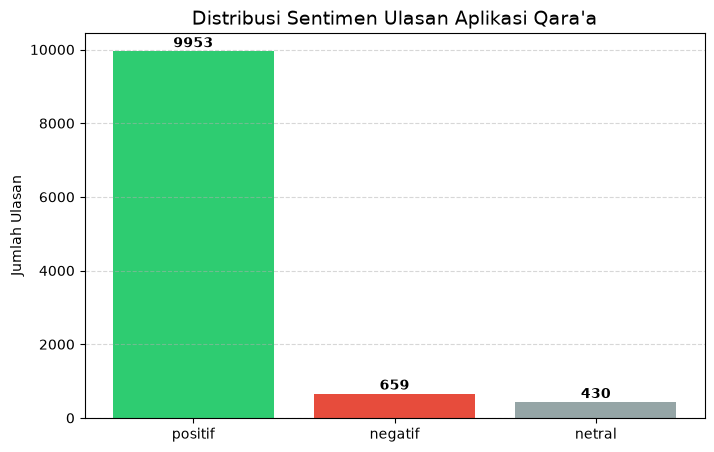

In [33]:
# hitung jumlah ulasan per label sentimen
sentimen_counts = df['label'].value_counts()

# tentukan warna tetap agar setiap label konsisten di semua grafik
warna_map = {'positif': '#2ecc71', 'negatif': '#e74c3c', 'netral': '#95a5a6'}
colors = [warna_map[label] for label in sentimen_counts.index]

plt.figure(figsize=(8, 5))
bars = plt.bar(sentimen_counts.index, sentimen_counts.values, color=colors)

# tampilkan jumlah ulasan di atas setiap batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 20, int(yval),
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Distribusi Sentimen Ulasan Aplikasi Qara'a", fontsize=14)
plt.ylabel('Jumlah Ulasan')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Proporsi Sentimen

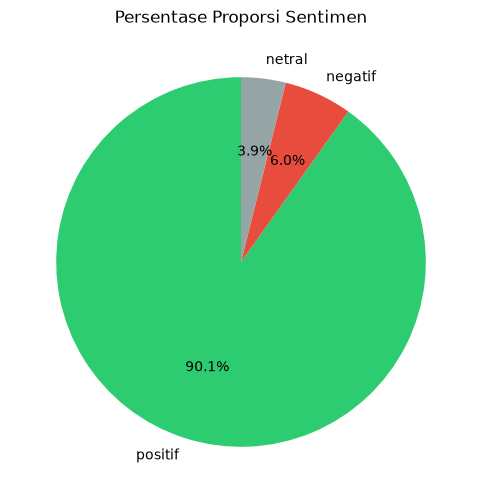

In [34]:
# pie chart proporsi sentimen dengan warna yang sama seperti bar chart
plt.figure(figsize=(6, 6))
plt.pie(sentimen_counts, labels=sentimen_counts.index, autopct='%1.1f%%',
        startangle=90, colors=colors)
plt.title('Persentase Proporsi Sentimen')
plt.show()

### Distribusi Sentimen per Fitur

In [35]:
# kata kunci tiap fitur aplikasi, dipisah dengan tanda |
fitur_dict = {
    'Materi Belajar': 'belajar|materi',
    "Baca Al-Qur'an": 'baca|alquran',
    'Sensor Suara': 'suara|rekam',
    'Notifikasi Adzan': 'adzan|notifikasi|alarm',
    'Layanan Premium': 'premium|langganan|bayar|iklan'
}

In [ ]:
# hitung jumlah sentimen pada ulasan yang mengandung kata kunci tiap fitur
kolom_teks = 'content_token'
data_fitur = []

for fitur, keywords in fitur_dict.items():
    df_fitur = df[df[kolom_teks].str.contains(keywords, case=False, na=False)]
    counts = df_fitur['label'].value_counts().to_dict()

    data_fitur.append({
        'Fitur': fitur,
        'positif': counts.get('positif', 0),
        'negatif': counts.get('negatif', 0),
        'netral': counts.get('netral', 0)
    })

# ubah hasil perhitungan menjadi dataframe untuk grafik
df_grafik = pd.DataFrame(data_fitur)

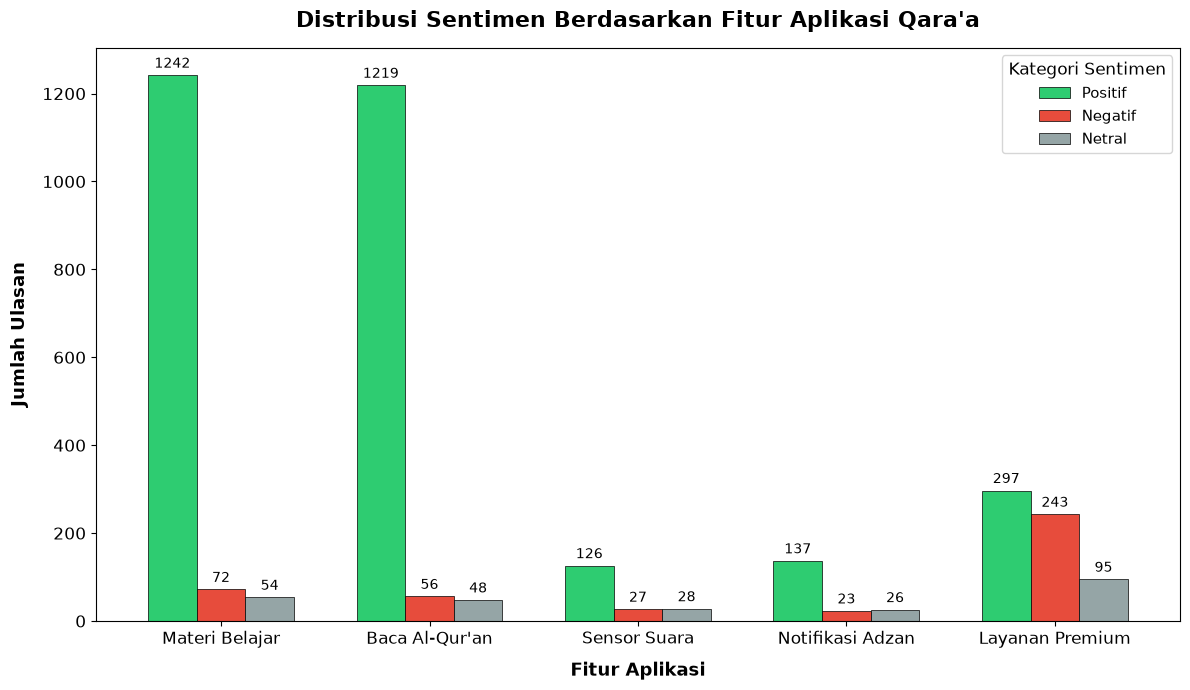

In [37]:
# warna urut sesuai kolom positif, negatif, netral
warna_sentimen = ['#2ecc71', '#e74c3c', '#95a5a6']

ax = df_grafik.set_index('Fitur').plot(
    kind='bar',
    stacked=False,
    figsize=(12, 7),
    color=warna_sentimen,
    width=0.7,
    edgecolor='black',
    linewidth=0.5
)

# atur judul, label sumbu, dan legenda agar rapi
plt.title("Distribusi Sentimen Berdasarkan Fitur Aplikasi Qara'a", fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Fitur Aplikasi', fontsize=13, fontweight='bold', labelpad=10)
plt.ylabel('Jumlah Ulasan', fontsize=13, fontweight='bold', labelpad=10)
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Kategori Sentimen', title_fontsize=12, fontsize=11, loc='upper right')

# tampilkan angka di atas batang yang nilainya lebih dari 0
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, color='black', xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()